# Baseline Local Outlier Factor — IEEE-CIS Fraud Detection

## Objective

Fit a baseline `scikit-learn` **LocalOutlierFactor** with default parameters on the same
feature matrix used for the Isolation Forest baseline, then sanity-check the scores
against the labels.

`isFraud` is withheld from fitting; it is only used afterwards for evaluation.


In [15]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import roc_auc_score
from sklearn.neighbors import LocalOutlierFactor

RNG_SEED = 42
np.random.seed(RNG_SEED)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100


## 1. Load data

In [16]:
DATA_DIR = "../../data/ieee-fraud-detection"

t0 = time.perf_counter()
tx = pd.read_csv(f"{DATA_DIR}/train_transaction.csv")
idt = pd.read_csv(f"{DATA_DIR}/train_identity.csv")
df = tx.merge(idt, on="TransactionID", how="left")
print(f"Loaded + merged in {time.perf_counter() - t0:.1f}s")
print(f"Merged shape: {df.shape}")


Loaded + merged in 11.2s
Merged shape: (590540, 434)


## 2. Data preparation

- Exclude `TransactionID` (identifier), `isFraud` (label), `TransactionDT` (timestamp).
- Drop columns missing in more than 90% of rows.
- Median imputation for numeric columns, simple ordinal (label) encoding for categorical
  columns.


In [17]:
EXCLUDE_COLS = ["TransactionID", "isFraud", "TransactionDT"]
MISSING_DROP_THRESHOLD = 0.90

y = df["isFraud"].copy()  # withheld from fitting; evaluation only

missing_pct = df.isna().mean()
cols_to_drop_missing = missing_pct[missing_pct > MISSING_DROP_THRESHOLD].index.tolist()
print(f"Dropping {len(cols_to_drop_missing)} columns with >{MISSING_DROP_THRESHOLD:.0%} missing")

work = df.drop(columns=EXCLUDE_COLS + cols_to_drop_missing)

numeric_cols = [c for c in work.columns if pd.api.types.is_numeric_dtype(work[c])]
categorical_cols = [c for c in work.columns if c not in numeric_cols]

X = work.copy()
X[numeric_cols] = X[numeric_cols].fillna(X[numeric_cols].median())
for col in categorical_cols:
    X[col] = pd.factorize(X[col].fillna("missing"))[0]

assert X.isna().sum().sum() == 0
assert X.shape == (590540, 419)
print(f"Feature matrix: {X.shape} "
      f"({len(numeric_cols)} numeric, {len(categorical_cols)} ordinal-encoded categorical)")


Dropping 12 columns with >90% missing
Feature matrix: (590540, 419) (390 numeric, 29 ordinal-encoded categorical)


## 3. Baseline LocalOutlierFactor (default parameters)

In [18]:
FIT_SIZE = 25000  # None = fit on every row

if FIT_SIZE is None:
    fit_idx = np.arange(len(X))
else:
    fit_idx = np.random.default_rng(RNG_SEED).choice(len(X), size=FIT_SIZE, replace=False)
X_fit, y_fit = X.iloc[fit_idx], y.iloc[fit_idx].values

t0 = time.perf_counter()
lof = LocalOutlierFactor()  # defaults: n_neighbors=20, contamination="auto", metric="minkowski"
lof.fit(X_fit)
print(f"Fit on {len(X_fit):,} rows in {time.perf_counter() - t0:.1f}s")

# LOF ~ 1: as dense as its neighbours (inlier); >> 1: much sparser than its neighbours.
scores = -lof.negative_outlier_factor_
print(f"LOF score range: [{scores.min():.3f}, {scores.max():.3f}], "
      f"median {np.median(scores):.3f}")


Fit on 25,000 rows in 2.8s
LOF score range: [0.943, 73.357], median 1.135


## 4. Score distribution

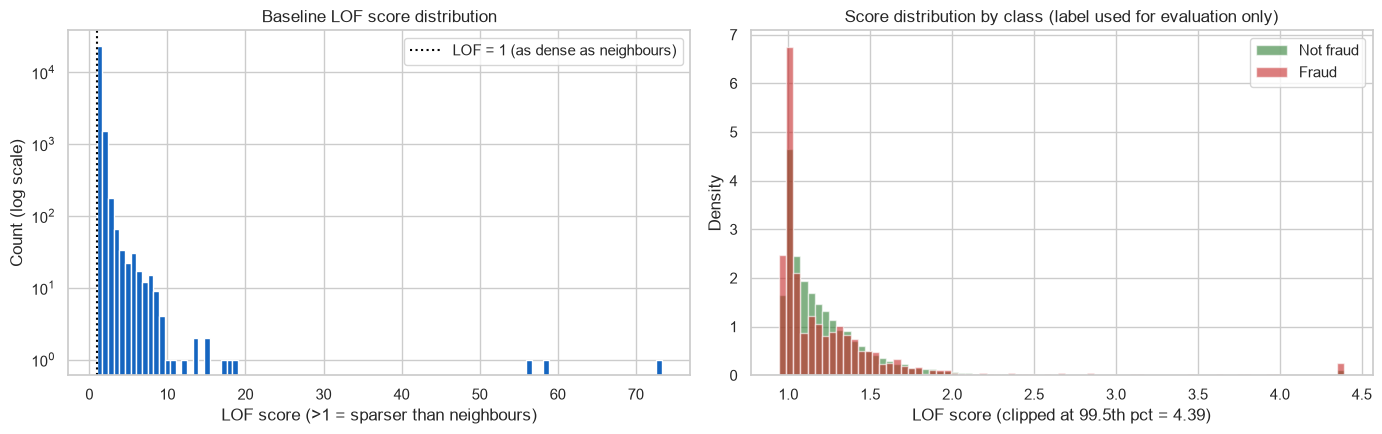

Mean score -- fraud: 1.284, non-fraud: 1.264
Median score -- fraud: 1.080, non-fraud: 1.136


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].hist(scores, bins=100, color="#1565C0")
axes[0].set_yscale("log")
axes[0].axvline(1, color="black", linestyle=":", label="LOF = 1 (as dense as neighbours)")
axes[0].set_xlabel("LOF score (>1 = sparser than neighbours)")
axes[0].set_ylabel("Count (log scale)")
axes[0].set_title("Baseline LOF score distribution")
axes[0].legend()

hi = np.quantile(scores, 0.995)  # clip the extreme tail so the bulk is visible
bins = np.linspace(scores.min(), hi, 80)
axes[1].hist(np.clip(scores[y_fit == 0], None, hi), bins=bins, density=True, alpha=0.6,
             color="#2E7D32", label="Not fraud")
axes[1].hist(np.clip(scores[y_fit == 1], None, hi), bins=bins, density=True, alpha=0.6,
             color="#C62828", label="Fraud")
axes[1].set_xlabel(f"LOF score (clipped at 99.5th pct = {hi:.2f})")
axes[1].set_ylabel("Density")
axes[1].set_title("Score distribution by class (label used for evaluation only)")
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"Mean score -- fraud: {scores[y_fit == 1].mean():.3f}, "
      f"non-fraud: {scores[y_fit == 0].mean():.3f}")
print(f"Median score -- fraud: {np.median(scores[y_fit == 1]):.3f}, "
      f"non-fraud: {np.median(scores[y_fit == 0]):.3f}")


**Findings:** the scores form a tight bulk just above 1 (median 1.135) with a long thin right tail out to ~73, so a handful of points are far sparser than their neighbours. Fraud and non-fraud overlap almost completely, and fraud's *median* score is actually slightly lower (1.080 vs. 1.136). Features are unscaled, so Euclidean distance is dominated by large-magnitude columns (e.g. `TransactionAmt`, some `V` columns), which limits what 'local density' means here.

### LOF score surface (UMAP layout)

The histograms above hide *where* high LOF scores sit in feature space. This reproduces the Isolation Forest notebook's UMAP so the two methods can be compared point for point


In [20]:
import umap
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Same subsample as the Isolation Forest notebook (N_VIZ=30000, rng seed 42 over df.index)
N_VIZ = 30000
viz_idx = np.random.default_rng(RNG_SEED).choice(df.index, size=N_VIZ, replace=False)

X_viz = X.loc[viz_idx]
viz_fraud = y.loc[viz_idx].values

X_viz_scaled = StandardScaler().fit_transform(X_viz)
pca_pre = PCA(n_components=50, random_state=RNG_SEED)
X_viz_pca50 = pca_pre.fit_transform(X_viz_scaled)
print(f"Visualization subsample: {N_VIZ:,} rows")
print(f"PCA pre-reduction: {X_viz.shape[1]} -> 50 components, "
      f"explaining {pca_pre.explained_variance_ratio_.sum() * 100:.1f}% of variance")

reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="euclidean", random_state=RNG_SEED)
embedding = reducer.fit_transform(X_viz_pca50)
print(f"UMAP embedding shape: {embedding.shape}")

# Baseline LOF (defaults) fit on the visualization rows so every plotted point has a score
viz_scores = -LocalOutlierFactor().fit(X_viz).negative_outlier_factor_
print(f"Viz LOF score range: [{viz_scores.min():.3f}, {viz_scores.max():.3f}], "
      f"median {np.median(viz_scores):.3f}")


Visualization subsample: 30,000 rows
PCA pre-reduction: 419 -> 50 components, explaining 80.9% of variance


/Users/joyce/Desktop/FraudDetection/Unsupervised-fraud-detection-the-outliers/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP embedding shape: (30000, 2)
Viz LOF score range: [0.942, 59.308], median 1.131


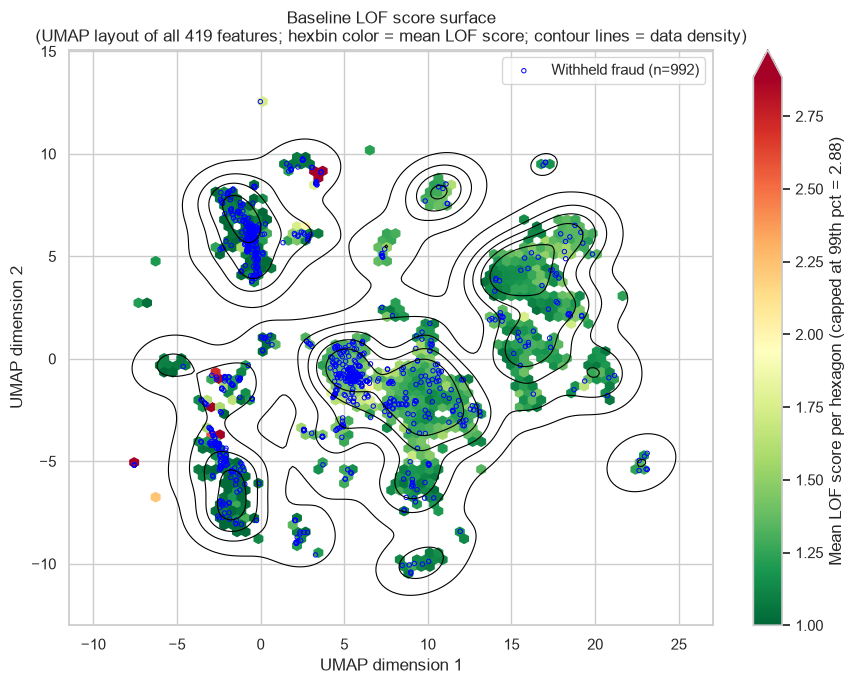

In [21]:
vmax = np.quantile(viz_scores, 0.99)  # cap the colour scale; the raw max (~73) would flatten everything else

fig, ax = plt.subplots(figsize=(9, 7))
hb = ax.hexbin(embedding[:, 0], embedding[:, 1], C=viz_scores, reduce_C_function=np.mean,
               gridsize=60, cmap="RdYlGn_r", mincnt=5, vmin=1, vmax=vmax)
plt.colorbar(hb, ax=ax, extend="max",
             label=f"Mean LOF score per hexagon (capped at 99th pct = {vmax:.2f})")

sns.kdeplot(x=embedding[:, 0], y=embedding[:, 1], levels=6, color="black", linewidths=0.8, ax=ax)

fraud_mask = viz_fraud == 1
ax.scatter(embedding[fraud_mask, 0], embedding[fraud_mask, 1], s=10, facecolors="none",
           edgecolors="blue", linewidths=0.7, label=f"Withheld fraud (n={fraud_mask.sum()})")

ax.set_xlabel("UMAP dimension 1")
ax.set_ylabel("UMAP dimension 2")
ax.set_title("Baseline LOF score surface\n"
             "(UMAP layout of all 419 features; hexbin color = mean LOF score; "
             "contour lines = data density)")
ax.legend(loc="best")
plt.tight_layout()
plt.show()


## 5. Sanity check against labels

In [22]:
base_rate = y_fit.mean()
auc = roc_auc_score(y_fit, scores)
print(f"Fraud base rate in fitted rows: {base_rate:.3%}")
print(f"ROC-AUC: {auc:.4f}\n")

order = np.argsort(-scores)
for label, k in [("top 10", 10), ("top 3.5%", int(round(0.035 * len(scores))))]:
    hits = int(y_fit[order[:k]].sum())
    print(f"{label:>9} (k={k:,}): {hits:,} fraud, precision {hits / k:.2%}, "
          f"lift {hits / k / base_rate:.2f}x vs. base rate, "
          f"recall {hits / y_fit.sum():.2%}")


Fraud base rate in fitted rows: 3.284%
ROC-AUC: 0.4563

   top 10 (k=10): 0 fraud, precision 0.00%, lift 0.00x vs. base rate, recall 0.00%
 top 3.5% (k=875): 41 fraud, precision 4.69%, lift 1.43x vs. base rate, recall 4.99%


**Findings:** ROC-AUC is **0.456**, below 0.5 and well below the Isolation Forest baseline (0.77): the default LOF ranking is no better than random for fraud. None of the top 10 is fraud. The top 3.5% contains 41 frauds (4.69% precision, 1.43x lift), a small gain over the 3.28% base rate that is not supported by the overall AUC. Fraud here does not appear as a local density outlier on raw, unscaled features. 